# El conjunto Rashomon: muchos modelos, muchas explicaciones

**Aprendizaje Automático · Doctorado en Ingeniería · Universidad de Talca**
Clase 13, unidad 6 · Genera la figura de la lámina «La explicación no es única»

---

La clase afirma que **dos modelos con el mismo desempeño pueden dar
explicaciones completamente distintas**, y que con atributos correlacionados ese
conjunto de modelos equivalentes —el *conjunto Rashomon*— es grande.

Es el argumento más fuerte de Rudin (2019): si hay muchos modelos igual de
buenos y discrepan sobre qué importa, ¿por qué creer la explicación del que usted
entrenó por azar?

Aquí se mide. Y se comprueba también la advertencia sobre la **importancia por
permutación** con atributos correlacionados.

## El diseño

| | |
|---|---|
| Atributos | 12, de los cuales **4 forman dos pares casi idénticos** |
| Verdaderamente causales | 5, con coeficientes conocidos |
| Casos | 2 000 |
| Modelos comparados | 6 familias, más 10 réplicas de la misma familia |

Los pares correlacionados son deliberados: son la situación de un banco de
sensores redundantes, y son donde la explicación se vuelve ambigua.

## 1. Entorno

In [1]:
import sys, platform
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import sklearn
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier, ExtraTreesClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.inspection import permutation_importance
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score

print("Python       ", sys.version.split()[0], "|", platform.system(), platform.machine())
print("numpy        ", np.__version__)
print("scikit-learn ", sklearn.__version__)

Python        3.12.14 | Darwin arm64
numpy         2.2.6
scikit-learn  1.9.0


In [2]:
SEMILLA = 26
N_CASOS = 2000
N_ATRIBUTOS = 12
RUIDO_COPIA = 0.05        # cuánto se aparta la copia de su original
N_REPLICAS = 10

nombres = [f"x{j}" for j in range(N_ATRIBUTOS)]
print(f"Atributos: {nombres}")
print(f"x1 será casi copia de x0;  x3 será casi copia de x2  (ruido {RUIDO_COPIA})")

Atributos: ['x0', 'x1', 'x2', 'x3', 'x4', 'x5', 'x6', 'x7', 'x8', 'x9', 'x10', 'x11']
x1 será casi copia de x0;  x3 será casi copia de x2  (ruido 0.05)


## 2. Los datos

Cinco atributos son causales con coeficientes conocidos. **`x1` es casi una copia
de `x0`, y `x3` casi una copia de `x2`**: cada par lleva la misma información.

La etiqueta depende de `x0` y de `x2`, **no** de sus copias. Pero como las copias
son casi idénticas, ningún método puede distinguir cuál del par usó el modelo.

In [3]:
rng = np.random.default_rng(SEMILLA)

X = rng.standard_normal((N_CASOS, N_ATRIBUTOS))
X[:, 1] = X[:, 0] + RUIDO_COPIA * rng.standard_normal(N_CASOS)   # copia de x0
X[:, 3] = X[:, 2] + RUIDO_COPIA * rng.standard_normal(N_CASOS)   # copia de x2

coef = np.zeros(N_ATRIBUTOS)
coef[0], coef[2], coef[4], coef[5], coef[6] = 1.4, -1.2, 0.9, 0.7, -0.6

z = X @ coef
z = (z - z.mean()) / z.std()
y = (rng.uniform(size=N_CASOS) < 1 / (1 + np.exp(-2.0 * z))).astype(int)

print("Coeficientes verdaderos (0 = no interviene):")
for j, c in enumerate(coef):
    marca = "   <- causal" if c != 0 else ("   (copia)" if j in (1, 3) else "")
    print(f"  {nombres[j]:>4} {c:>6.1f}{marca}")
print(f"\nCorrelación x0-x1: {np.corrcoef(X[:,0], X[:,1])[0,1]:.4f}")
print(f"Correlación x2-x3: {np.corrcoef(X[:,2], X[:,3])[0,1]:.4f}")
print(f"Proporción de positivos: {y.mean():.3f}")

Coeficientes verdaderos (0 = no interviene):
    x0    1.4   <- causal
    x1    0.0   (copia)
    x2   -1.2   <- causal
    x3    0.0   (copia)
    x4    0.9   <- causal
    x5    0.7   <- causal
    x6   -0.6   <- causal
    x7    0.0
    x8    0.0
    x9    0.0
   x10    0.0
   x11    0.0

Correlación x0-x1: 0.9987
Correlación x2-x3: 0.9987
Proporción de positivos: 0.490


## 3. Seis modelos de desempeño equivalente

In [4]:
X_ent, X_pru, y_ent, y_pru = train_test_split(X, y, test_size=0.3,
                                              stratify=y, random_state=0)

modelos = {
    "Logística":       make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
    "Bosque":          RandomForestClassifier(n_estimators=300, random_state=0, n_jobs=-1),
    "Árboles extra":   ExtraTreesClassifier(n_estimators=300, random_state=0, n_jobs=-1),
    "Potenciación":    HistGradientBoostingClassifier(random_state=0),
    "Red (64,32)":     make_pipeline(StandardScaler(),
                          MLPClassifier(hidden_layer_sizes=(64, 32), max_iter=600,
                                        early_stopping=True, random_state=0)),
    "Red (128,)":      make_pipeline(StandardScaler(),
                          MLPClassifier(hidden_layer_sizes=(128,), max_iter=600,
                                        early_stopping=True, random_state=1)),
}

aucs, importancias = {}, {}
for nombre, m in modelos.items():
    m.fit(X_ent, y_ent)
    aucs[nombre] = roc_auc_score(y_pru, m.predict_proba(X_pru)[:, 1])
    r = permutation_importance(m, X_pru, y_pru, n_repeats=10,
                               random_state=0, scoring="roc_auc", n_jobs=-1)
    importancias[nombre] = np.clip(r.importances_mean, 0, None)

print(f"{'modelo':>16} {'AUC':>9}")
print("-" * 27)
for nombre in modelos:
    print(f"{nombre:>16} {aucs[nombre]:>9.4f}")
print()
print(f"Diferencia entre el mejor y el peor: {max(aucs.values()) - min(aucs.values()):.4f}")

          modelo       AUC
---------------------------
       Logística    0.8695
          Bosque    0.8396
   Árboles extra    0.8454
    Potenciación    0.8282
     Red (64,32)    0.8692
      Red (128,)    0.8631

Diferencia entre el mejor y el peor: 0.0413


**Los seis modelos rinden casi igual.** Es el conjunto Rashomon: un conjunto de
modelos que los datos no permiten distinguir.

Ahora se comparan sus explicaciones.

In [5]:
print(f"{'atributo':>9} {'verdad':>8} " + "".join(f"{n[:11]:>12}" for n in modelos))
print("-" * (18 + 12 * len(modelos)))
for j in range(N_ATRIBUTOS):
    fila = "".join(f"{importancias[n][j] / max(importancias[n].max(), 1e-12):>12.2f}"
                   for n in modelos)
    etiqueta = f"{coef[j]:>8.1f}" if coef[j] != 0 else ("  (copia)" if j in (1, 3) else "       .")
    print(f"{nombres[j]:>9} {etiqueta}{fila}")
print()
print("Importancias normalizadas al máximo de cada modelo.")

 atributo   verdad    Logística      Bosque Árboles ext Potenciació Red (64,32)  Red (128,)
------------------------------------------------------------------------------------------
       x0      1.4        1.00        0.75        0.64        0.95        0.14        0.90
       x1   (copia)        0.13        0.76        0.80        0.70        1.00        0.44
       x2     -1.2        0.37        0.66        0.71        0.84        0.52        0.53
       x3   (copia)        0.46        0.63        0.62        0.48        0.32        0.69
       x4      0.9        0.77        1.00        1.00        1.00        0.70        1.00
       x5      0.7        0.33        0.48        0.50        0.48        0.33        0.44
       x6     -0.6        0.32        0.32        0.38        0.35        0.32        0.40
       x7        .        0.00        0.00        0.00        0.00        0.00        0.00
       x8        .        0.00        0.00        0.00        0.06        0.04        0

Mire las filas de **`x0`/`x1`** y de **`x2`/`x3`**. Los modelos no coinciden en
cuál del par es el importante: unos cargan sobre el original, otros sobre la
copia, y otros reparten.

Ningún método puede resolverlo, porque **la información es la misma**. Y sin
embargo cada modelo entrega una explicación con aspecto de respuesta.

## 4. La misma familia, distinta semilla

El desacuerdo no viene solo de comparar familias distintas. Se entrenan **10
bosques idénticos salvo la semilla** y se comparan sus explicaciones.

In [6]:
imp_replicas = []
auc_replicas = []
for s in range(N_REPLICAS):
    m = RandomForestClassifier(n_estimators=300, random_state=s, n_jobs=-1).fit(X_ent, y_ent)
    auc_replicas.append(roc_auc_score(y_pru, m.predict_proba(X_pru)[:, 1]))
    r = permutation_importance(m, X_pru, y_pru, n_repeats=8,
                               random_state=0, scoring="roc_auc", n_jobs=-1)
    v = np.clip(r.importances_mean, 0, None)
    imp_replicas.append(v / max(v.max(), 1e-12))
imp_replicas = np.array(imp_replicas)

print(f"AUC de las {N_REPLICAS} réplicas: "
      f"{np.mean(auc_replicas):.4f} ± {np.std(auc_replicas):.4f}")
print()
print(f"{'atributo':>9} {'mediana':>10} {'mín':>8} {'máx':>8} {'rango':>8}")
print("-" * 46)
for j in [0, 1, 2, 3, 4, 6]:
    col = imp_replicas[:, j]
    print(f"{nombres[j]:>9} {np.median(col):>10.2f} {col.min():>8.2f} "
          f"{col.max():>8.2f} {col.max()-col.min():>8.2f}")

AUC de las 10 réplicas: 0.8398 ± 0.0020

 atributo    mediana      mín      máx    rango
----------------------------------------------
       x0       0.74     0.64     0.90     0.26
       x1       0.76     0.59     0.84     0.25
       x2       0.63     0.51     0.71     0.20
       x3       0.62     0.49     0.66     0.17
       x4       1.00     1.00     1.00     0.00
       x6       0.33     0.31     0.39     0.07


## 5. Cuánto discrepan, medido

Se cuantifica el desacuerdo de dos formas: la **correlación de rangos** entre
explicaciones, y si **coinciden en cuál es el atributo más importante**.

In [7]:
from scipy.stats import spearmanr
from itertools import combinations

nombres_m = list(modelos)
rho = []
for a, b in combinations(nombres_m, 2):
    rho.append(spearmanr(importancias[a], importancias[b]).statistic)
rho = np.array(rho)

top1 = {n: nombres[int(np.argmax(importancias[n]))] for n in nombres_m}
print("Atributo señalado como más importante por cada modelo:")
for n in nombres_m:
    print(f"  {n:>16} -> {top1[n]}")
print()
print(f"Modelos que coinciden en el más importante: "
      f"{len(set(top1.values()))} respuestas distintas de {len(nombres_m)} modelos")
print()
print(f"Correlación de rangos entre explicaciones (Spearman), sobre "
      f"{len(rho)} pares de modelos:")
print(f"  mediana {np.median(rho):.3f}   mínima {rho.min():.3f}   máxima {rho.max():.3f}")

Atributo señalado como más importante por cada modelo:
         Logística -> x0
            Bosque -> x4
     Árboles extra -> x4
      Potenciación -> x4
       Red (64,32) -> x1
        Red (128,) -> x4

Modelos que coinciden en el más importante: 3 respuestas distintas de 6 modelos

Correlación de rangos entre explicaciones (Spearman), sobre 15 pares de modelos:
  mediana 0.875   mínima 0.693   máxima 0.974


## 6. Figura

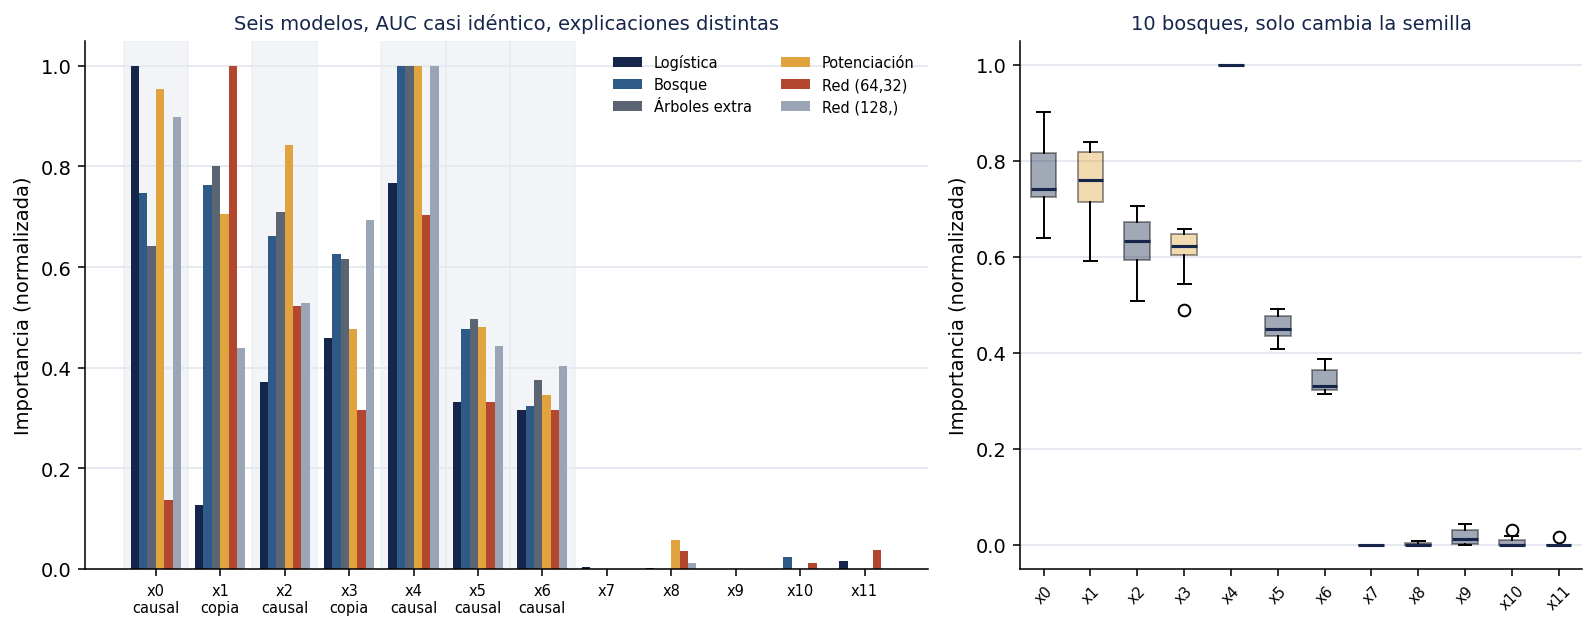

In [8]:
#| label: fig-rashomon
#| fig-cap: "Importancia por permutación de seis modelos con desempeño equivalente."
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11.5, 4.6), dpi=140,
                             gridspec_kw={"width_ratios": [1.5, 1]})

x = np.arange(N_ATRIBUTOS)
ancho = 0.13
colores = ["#16264A", "#2E5A87", "#5B6472", "#E0A33E", "#B3462F", "#9AA5B5"]
for i, (nombre, color) in enumerate(zip(nombres_m, colores)):
    v = importancias[nombre] / max(importancias[nombre].max(), 1e-12)
    a1.bar(x + (i - 2.5) * ancho, v, ancho, color=color, label=nombre)

for j in range(N_ATRIBUTOS):
    if coef[j] != 0:
        a1.axvspan(j - 0.5, j + 0.5, color="#E6EAF0", alpha=0.5, zorder=0)
a1.set_xticks(x)
a1.set_xticklabels([f"{n}\n{'causal' if coef[j] != 0 else ('copia' if j in (1,3) else '')}"
                    for j, n in enumerate(nombres)], fontsize=7.5)
a1.set_ylabel("Importancia (normalizada)")
a1.set_title("Seis modelos, AUC casi idéntico, explicaciones distintas",
             fontsize=10, color="#16264A")
a1.spines[["top", "right"]].set_visible(False)
a1.grid(axis="y", color="#E6EAF0", lw=1); a1.set_axisbelow(True)
a1.legend(frameon=False, fontsize=7.5, ncol=2)

partes = a2.boxplot([imp_replicas[:, j] for j in range(N_ATRIBUTOS)],
                    tick_labels=nombres, widths=0.55, patch_artist=True,
                    medianprops=dict(color="#16264A", lw=1.6))
for j, parche in enumerate(partes["boxes"]):
    parche.set_facecolor("#E0A33E" if j in (1, 3) else "#16264A")
    parche.set_alpha(0.4)
a2.set_ylabel("Importancia (normalizada)")
a2.set_title(f"{N_REPLICAS} bosques, solo cambia la semilla", fontsize=10, color="#16264A")
a2.tick_params(axis="x", labelsize=7.5, rotation=45)
a2.spines[["top", "right"]].set_visible(False)
a2.grid(axis="y", color="#E6EAF0", lw=1); a2.set_axisbelow(True)

fig.tight_layout()
fig.savefig("conjunto_rashomon.png", dpi=200, bbox_inches="tight")
plt.show()

Las bandas grises marcan los atributos **realmente causales**. Las cajas ámbar
del panel derecho son las **copias**, que no intervienen en generar la etiqueta.

Dos cosas que leer:

- Los modelos coinciden razonablemente en **descartar** los atributos que no
  intervienen. Eso está bien, y es el uso legítimo de estos métodos: **depurar**.
- Pero **no coinciden en repartir** entre un atributo y su copia. Y no pueden:
  la información es la misma, así que la pregunta «¿cuál de los dos importa?» no
  tiene respuesta en los datos.

Si su explicación va a fundamentar una intervención —«baje `x0`»— esa ambigüedad
es exactamente el problema que Rudin señala.

## 7. Bitácora

**Decisiones tomadas**

1. *Dos pares de atributos casi idénticos.* Es el mecanismo que hace grande el
   conjunto Rashomon, y es la situación normal en instrumentación: sensores
   redundantes que miden lo mismo. Sin correlación, los modelos coincidirían y el
   cuaderno no mostraría nada.
2. *Importancia por permutación y no SHAP.* `shap` no está en el entorno del
   módulo, y añadir una dependencia por una figura no se justifica. La permutación
   sufre **el mismo problema** con atributos correlacionados —permutar uno no
   destruye la información, que sigue en su copia— así que el argumento se sostiene
   igual. En un trabajo con SHAP habría que declarar además qué aproximación se usó.
3. *Importancias normalizadas al máximo de cada modelo.* Las escalas absolutas no
   son comparables entre familias; lo que interesa es el **orden** y el reparto.
4. *Se recortan las importancias negativas a cero.* La permutación puede dar
   valores negativos por ruido de estimación, y no tienen interpretación.
5. *Diez réplicas de la misma familia además de seis familias distintas.* Separa
   dos fuentes de desacuerdo: entre familias y **dentro** de una familia. La
   segunda es la más incómoda, porque no se puede atribuir a «modelos distintos».

**Decisión alternativa descartada** — ítem 7 de la lista de cotejo

Se consideró usar coeficientes de una regresión como explicación de referencia
«correcta», para medir el error de cada método frente a ella. **Se descartó**
porque presupone lo que se quiere discutir: que existe una explicación correcta
del modelo. Lo que el cuaderno muestra es precisamente que **la pregunta está mal
planteada** cuando dos atributos llevan la misma información. Los coeficientes
verdaderos se usan solo para marcar qué atributos intervienen y cuáles no, que sí
es un hecho del generador de datos.

**Uso de asistentes de IA**

Declarar aquí en qué parte del trabajo se usaron, según la regla operativa del
módulo.

## 8. Verificación

In [9]:
# 1. El conjunto Rashomon existe: los modelos rinden casi igual.
rango_auc = max(aucs.values()) - min(aucs.values())
assert rango_auc < 0.06, "Los modelos deberían tener desempeño comparable."

# 2. Y sin embargo no coinciden en el reparto entre un atributo y su copia.
reparto = {n: importancias[n][0] / max(importancias[n][0] + importancias[n][1], 1e-12)
           for n in nombres_m}
assert max(reparto.values()) - min(reparto.values()) > 0.25, \
    "Los modelos deberían discrepar en cómo reparten entre x0 y su copia x1."

# 3. Los métodos sí coinciden en descartar lo que no interviene: uso legítimo.
irrelevantes = [j for j in range(N_ATRIBUTOS) if coef[j] == 0 and j not in (1, 3)]
for n in nombres_m:
    v = importancias[n] / max(importancias[n].max(), 1e-12)
    assert v[irrelevantes].max() < 0.5, \
        f"{n} asigna demasiada importancia a un atributo que no interviene."

print("Verificado:")
print(f"  - rango de AUC entre los 6 modelos: {rango_auc:.4f}  (son equivalentes);")
print(f"  - reparto de importancia entre x0 y su copia x1:")
for n in nombres_m:
    print(f"      {n:>16}: {100*reparto[n]:>5.1f} % a x0")
print(f"  - todos descartan correctamente los atributos que no intervienen.")

Verificado:
  - rango de AUC entre los 6 modelos: 0.0413  (son equivalentes);
  - reparto de importancia entre x0 y su copia x1:
             Logística:  88.8 % a x0
                Bosque:  49.5 % a x0
         Árboles extra:  44.5 % a x0
          Potenciación:  57.5 % a x0
           Red (64,32):  12.1 % a x0
            Red (128,):  67.2 % a x0
  - todos descartan correctamente los atributos que no intervienen.
